# ETF volatility

Online prediction intervals for absolute daily log returns of SPY, QQQ, IWM, EEM, and TLT.


In [1]:
# Locate the project root.
from pathlib import Path
import sys
_PROJECT_CANDIDATES = (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent)
PROJECT_ROOT = next((p for p in _PROJECT_CANDIDATES if (p / "cp_methods.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project directory.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "data"

import contextlib
from functools import partial
from importlib.metadata import version
import io
from pathlib import Path
import platform
import time

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

import cp_methods as cpm

DATA_DIR = PROJECT_ROOT / "data"
TICKERS = ["SPY", "QQQ", "IWM", "EEM", "TLT"]
START = "2008-01-01"
END = "2026-03-06"
TRAIN_END = "2018-12-31"
TEST_START = "2020-01-01"
ALPHA = 0.10
R = 400
EWMA_SPAN = 20
WARMUP = 60
SEEDS = [104729, 130363, 155921, 181081, 205759]
BOOTSTRAP_SEEDS = {
    "cp": 42, "cop": 1042, "lqt": 2042, "lcp": 3042,
    "aci": 4042, "dtaci": 5042, "olcp": 6042, "olcph": 7042, "spci": 8042,
}
BOOT_REPS = 1_000
BOOT_BLOCK_LEN = 20
ROLLING_WINDOW = 20
SPCI_W_LAG = 30
SPCI_REFIT_EVERY = 5
N_THREADS = 1

METHOD_ORDER = ["cp", "lcp", "aci", "dtaci", "cop", "lqt", "spci", "olcp", "olcph"]
LABELS = {
    "cp": "CP", "lcp": "LCP", "aci": "ACI", "dtaci": "DtACI",
    "cop": "COP", "lqt": "LQT", "spci": "SPCI",
    "olcp": "OLCP", "olcph": "OLCP-Hedge",
}
METHOD_RUNNERS = {
    "cp": cpm.eval_cp, "cop": cpm.eval_cop, "lqt": cpm.eval_lqt,
    "lcp": cpm.eval_lcp, "aci": cpm.eval_aci, "dtaci": cpm.eval_dtaci,
    "spci": partial(
        cpm.eval_spci, w_lag=SPCI_W_LAG, T_train=R,
        refit_every=SPCI_REFIT_EVERY, beta_grid_size=21,
        rf_kwargs={"n_estimators": 80, "max_depth": 10, "min_samples_leaf": 5,
                   "random_state": 42, "n_jobs": N_THREADS},
    ),
    "olcp": cpm.eval_olcp, "olcph": cpm.eval_olcp_adahedge,
}

packages = ("numpy", "pandas", "matplotlib", "scikit-learn", "quantile-forest", "threadpoolctl", "tqdm")
print(f"Python {platform.python_version()} | numerical threads: {N_THREADS}")
print(" | ".join(f"{name} {version(name)}" for name in packages))


Python 3.11.14 | numerical threads: 1
numpy 1.26.4 | pandas 2.3.3 | matplotlib 3.10.7 | scikit-learn 1.7.2 | quantile-forest 1.4.1 | threadpoolctl 3.6.0 | tqdm 4.67.1


## Data and forecasts

The point forecast is $\sqrt{2/\pi}\,\sqrt{\operatorname{EWMA}_{20}(r^2)}$, using lagged returns. The eight previsible localization features summarize lagged VIX, EWMA absolute returns, past forecast errors, and the current forecast. Response normalization uses training statistics through 2018; online evaluation begins in January 2020.


In [2]:
required_files = ["VIX.csv"] + [f"{ticker.lower()}_us_d.csv" for ticker in TICKERS]
missing = [filename for filename in required_files if not (DATA_DIR / filename).is_file()]
if missing:
    raise FileNotFoundError(f"Place these CSVs in DATA_DIR: {missing}")

def prepare_selected_data():
    prices = pd.concat([
        pd.read_csv(DATA_DIR / f'{ticker.lower()}_us_d.csv', parse_dates=['Date'])
        .set_index('Date')['Close'].rename(ticker)
        for ticker in TICKERS
    ], axis=1).sort_index().dropna(how='all').ffill().loc[START:END]

    vix_source = pd.read_csv(DATA_DIR / 'VIX.csv')
    vix_source['Date'] = pd.to_datetime(vix_source['Date'], format='%m/%d/%y')
    vix_source = vix_source.set_index('Date')[' Close'].sort_index().astype(float).ffill()
    prices = prices.loc[prices.index.intersection(vix_source.index)]
    grid = pd.date_range(prices.index.min(), prices.index.max(), freq='B', name='Date')
    close = prices.reindex(grid).ffill()
    returns = np.log(close).diff().iloc[1:]
    volatility = returns.abs()
    lagged_vix = vix_source.reindex(grid).ffill().shift(1).reindex(volatility.index)

    data, zstats, frames = [], [], []
    for sid, ticker in enumerate(TICKERS):
        target = volatility[ticker]
        training = target.loc[:TRAIN_END]
        mu = float(training.mean())
        sd = float(training.std(ddof=0))
        if not np.isfinite(sd) or sd <= 0:
            raise ValueError(f"Invalid training scale for {ticker}.")
        zstats.append((mu, sd))
        past = target.shift(1)
        variance = returns[ticker].shift(1).pow(2).ewm(span=EWMA_SPAN, adjust=False).mean()
        forecast = (np.sqrt(variance) * np.sqrt(2/np.pi) - mu) / sd

        f = pd.DataFrame({
            'sid': sid,
            'raw_y': target,
            'y': (target - mu) / sd,
            'vix': lagged_vix,
            'ewm5': (past.ewm(span=5, adjust=False).mean() - mu) / sd,
            'ewm20': (past.ewm(span=20, adjust=False).mean() - mu) / sd,
            'ratio': (past.ewm(span=5, adjust=False).mean() + 1e-5)
                     / (past.ewm(span=60, adjust=False).mean() + 1e-5),
            'prediction': np.maximum(forecast.to_numpy(), -mu/sd),
        }, index=volatility.index)
        f = f.loc[target.shift(WARMUP).notna()].dropna()
        frames.append(f)
        y = f['y'].to_numpy()
        pred = f['prediction'].to_numpy()
        past_score = pd.Series(np.abs(y - pred), index=f.index).shift(1)
        state = np.column_stack([np.log(f['vix'].to_numpy()), f['ewm5'], f['ewm20'], f['ratio']])
        X = np.column_stack([
            state,
            past_score.to_numpy(),
            past_score.ewm(span=5, adjust=False).mean().to_numpy(),
            past_score.ewm(span=20, adjust=False).mean().to_numpy(),
            pred,
        ])
        valid = np.isfinite(X).all(axis=1)
        before = np.flatnonzero((f.index < TEST_START) & valid)[-R:]
        current = np.flatnonzero((f.index >= TEST_START) & (f.index <= END) & valid)
        keep = np.concatenate([before, current])
        if len(before) != R or len(current) <= SPCI_W_LAG + 1:
            raise ValueError(f"Insufficient pretest or test history for {ticker}.")
        times = f.index[keep]
        data.append({
            'series_id': sid,
            'ts': times,
            'y': y[keep],
            'pred': pred[keep],
            'score': np.abs(y[keep] - pred[keep]),
            'X': X[keep],
            'is_test': np.asarray(times >= TEST_START),
            'const_test': False,
        })

    frame = pd.concat(frames).sort_index(kind='stable')
    return data, zstats, frame



start = time.perf_counter()
data, zstats, frame = prepare_selected_data()
preparation_seconds = time.perf_counter() - start
for item in data:
    if not all(np.isfinite(item[key]).all() for key in ("y", "pred", "score", "X")):
        raise ValueError("Conformal inputs must be finite.")
    if item["ts"].duplicated().any():
        raise ValueError("Duplicate input dates.")
print(f"Data/forecast preparation: {preparation_seconds:.3f} s")
for item in data:
    print(f"{TICKERS[item['series_id']]}: {item['is_test'].sum():,} test dates | {item['X'].shape[1]} features | R={R}")


Data/forecast preparation: 0.055 s
SPY: 1,613 test dates | 8 features | R=400
QQQ: 1,613 test dates | 8 features | R=400
IWM: 1,613 test dates | 8 features | R=400
EEM: 1,613 test dates | 8 features | R=400
TLT: 1,613 test dates | 8 features | R=400


## Online methods

Nine methods; target coverage 90%, calibration window $R=400$. The preceding 400 pretest observations initialize localization. SPCI refits every five observations; OLCP-Hedge is evaluated with five fixed random seeds.


In [3]:
time_maps = {item["series_id"]: item["ts"] for item in data}
scales = np.array([sd for _, sd in zstats])
raw_results_by_seed, runtimes = {}, {name: [] for name in METHOD_ORDER}
with threadpool_limits(limits=N_THREADS):
    for seed in SEEDS:
        seed_results = {}
        for name, runner in METHOD_RUNNERS.items():
            np.random.seed(seed)
            if seed != SEEDS[0] and name != "olcph":
                seed_results[name] = raw_results_by_seed[SEEDS[0]][name]
                continue
            print(f"Running {LABELS[name]} (seed={seed})...", flush=True)
            with contextlib.redirect_stdout(io.StringIO()):
                result, seconds = runner(
                    data, alpha=ALPHA, R=R, exclude_const_test=False, show_pbar=False,
                )
            result = result.copy()
            result["date"] = pd.to_datetime([
                time_maps[int(sid)][int(t)] for sid, t in zip(result["series_id"], result["t"])
            ])
            if result.empty or result.duplicated(["date", "series_id"]).any():
                raise ValueError(f"{LABELS[name]} returned empty or duplicate observations.")
            if result[["lower", "upper", "width"]].isna().any().any() or (result["width"] < 0).any():
                raise ValueError(f"{LABELS[name]} returned invalid intervals.")
            # Preserve unbounded widths; exclude them only when computing finite-size summaries.
            result["size_pp"] = 100 * result["width"] * scales[result["series_id"].to_numpy(dtype=int)]
            seed_results[name] = result
            runtimes[name].append(float(seconds))
        raw_results_by_seed[seed] = seed_results

results_by_seed = raw_results_by_seed
results = results_by_seed[SEEDS[0]]
print(f"Completed nine methods over {len(TICKERS)} ETFs and {len(SEEDS)} fixed seeds.")
print(f"Bootstrap summary seed: {SEEDS[0]}; native evaluation rows are retained.")


Running CP (seed=104729)...
Running COP (seed=104729)...
Running LQT (seed=104729)...
Running LCP (seed=104729)...
Running ACI (seed=104729)...
Running DtACI (seed=104729)...
Running SPCI (seed=104729)...
Running OLCP (seed=104729)...
Running OLCP-Hedge (seed=104729)...
Running OLCP-Hedge (seed=130363)...
Running OLCP-Hedge (seed=155921)...
Running OLCP-Hedge (seed=181081)...
Running OLCP-Hedge (seed=205759)...
Completed nine methods over 5 ETFs and 5 fixed seeds.
Bootstrap summary seed: 104729; native evaluation rows are retained.


## Results

Equal-weight ETF averages of coverage and interval width (percentage points of absolute log return). Standard errors use 1,000 moving-block bootstrap replicates (length 20), sampled separately within each ETF.


In [4]:
def finite_mean(values, axis=0):
    finite = np.isfinite(values)
    counts = finite.sum(axis=axis)
    return np.divide(
        np.where(finite, values, 0.0).sum(axis=axis), counts,
        out=np.full(np.shape(counts), np.nan), where=counts > 0,
    )


def metric_means(groups, indices_by_etf, regime="All"):
    """Equal-ETF means of coverage and finite interval size."""
    coverage, size = [], []
    for group, indices in zip(groups, indices_by_etf):
        selected = indices[group["masks"][regime][indices]]
        coverage.append(group["coverage"][selected].mean() if len(selected) else np.nan)
        size.append(float(finite_mean(group["size"][selected])))
    return np.array([np.mean(coverage), float(finite_mean(np.asarray(size)))])


def bootstrap_one_method(result, bootstrap_seed, repetitions=BOOT_REPS, block_len=BOOT_BLOCK_LEN):
    """Original independent-ETF moving-block bootstrap; first model seed only."""
    groups = []
    for sid, group in result.groupby("series_id", sort=True):
        group = group.sort_values("t")
        vix = vix_values.reindex(pd.DatetimeIndex(group["date"])).to_numpy()
        if not np.isfinite(vix).all():
            raise ValueError("Missing lagged VIX on evaluation dates.")
        groups.append({
            "coverage": group["covered"].to_numpy(dtype=float),
            "size": group["size_pp"].to_numpy(dtype=float),
            "masks": {"All": np.ones(len(group), dtype=bool),
                      "Low VIX": vix <= low_threshold, "High VIX": vix >= high_threshold},
        })
    if len(groups) != len(TICKERS) or repetitions < 2 or block_len < 1:
        raise ValueError("Invalid bootstrap inputs.")
    rng = np.random.default_rng(bootstrap_seed)
    regimes = ("All", "Low VIX", "High VIX")
    draws = {regime: np.empty((repetitions, 2)) for regime in regimes}
    for b in range(repetitions):
        indices_by_etf = []
        for group in groups:
            length = len(group["coverage"])
            block = min(block_len, length)
            starts = rng.integers(0, length - block + 1, size=int(np.ceil(length / block)))
            indices = (starts[:, None] + np.arange(block)).ravel()[:length]
            indices_by_etf.append(indices)
        # Additional regime summaries consume no RNG draws, preserving the original stream.
        for regime in regimes:
            draws[regime][b] = metric_means(groups, indices_by_etf, regime)
    output = {}
    full_indices = [np.arange(len(group["coverage"])) for group in groups]
    for regime in regimes:
        means = metric_means(groups, full_indices, regime)
        se = np.array([column[np.isfinite(column)].std(ddof=1)
                       if np.isfinite(column).sum() > 1 else np.nan
                       for column in draws[regime].T])
        widths = np.concatenate([group["size"][group["masks"][regime]] for group in groups])
        output[regime] = {
            "coverage": means[0], "size": means[1],
            "coverage_se": se[0], "size_se": se[1],
            "observations": len(widths),
            "nonfinite_pct": 100 * (~np.isfinite(widths)).mean(),
        }
    return output


# Original regime thresholds: quartiles of lagged VIX over CP's native ETF-date rows.
vix_values = frame.loc[frame["sid"].eq(0), "vix"]
low_threshold, high_threshold = vix_values.reindex(results["cp"]["date"]).quantile([0.25, 0.75])
if low_threshold >= high_threshold:
    raise ValueError("VIX quartiles must define distinct regimes.")
method_stats = {
    name: bootstrap_one_method(results[name], BOOTSTRAP_SEEDS[name])
    for name in METHOD_ORDER
}
summary = pd.DataFrame([
    {"Method": LABELS[name],
     "Coverage": method_stats[name]["All"]["coverage"],
     "Coverage SE": method_stats[name]["All"]["coverage_se"],
     "Average finite size (pp)": method_stats[name]["All"]["size"],
     "Size SE (pp)": method_stats[name]["All"]["size_se"],
     "Nonfinite intervals (%)": method_stats[name]["All"]["nonfinite_pct"],
     "Runtime (s)": np.mean(runtimes[name]),
     "ETF-date observations": method_stats[name]["All"]["observations"]}
    for name in METHOD_ORDER
]).set_index("Method")
FORMATS = {"Coverage": "{:.4f}", "Coverage SE": "{:.4f}",
           "Average finite size (pp)": "{:.4f}", "Size SE (pp)": "{:.4f}",
           "Nonfinite intervals (%)": "{:.2f}", "Runtime (s)": "{:.3f}",
           "ETF-date observations": "{:,.0f}"}
display(summary.style.format(FORMATS, na_rep="undefined"))


,Coverage,Coverage SE,Average finite size (pp),Size SE (pp),Nonfinite intervals (%),Runtime (s),ETF-date observations
Method,,,,,,,
CP,0.9096,0.0058,2.8784,0.0590,0.00,0.108,"8,060"
LCP,0.9043,0.0040,2.4496,0.0544,0.00,0.332,"8,060"
ACI,0.9030,0.0048,2.6770,0.0870,0.00,0.088,"8,060"
DtACI,0.9022,0.0044,2.5941,0.0811,0.00,0.147,"8,060"
COP,0.8916,0.0032,2.4044,0.0517,0.00,0.047,"8,060"
LQT,0.9002,0.0036,2.4605,0.0560,0.00,0.039,"8,065"
SPCI,0.8566,0.0058,2.3431,0.0475,0.00,273.999,"7,910"
OLCP,0.9015,0.0038,2.4415,0.0725,0.00,0.363,"8,060"
OLCP-Hedge,0.9014,0.0037,2.4404,0.0693,0.00,0.818,"8,060"


## Projection diagnostics

Normalized boundary corrections and activation frequencies for ACI and OLCP.


In [5]:
boundary_rows = []
for name in ("aci", "olcp"):
    result = results_by_seed[SEEDS[0]][name]
    boundary_rows.append({
        "Method": LABELS[name],
        "L_bar": (result["L_t"] / result["gamma"]).mean(),
        "U_bar": (result["U_t"] / result["gamma"]).mean(),
        "f_L": result["L_hit"].mean(), "f_U": result["U_hit"].mean(),
    })
boundary_diagnostics = pd.DataFrame(boundary_rows).set_index("Method")
display(boundary_diagnostics.style.format("{:.6f}"))


,L_bar,U_bar,f_L,f_U
Method,,,,
ACI,0.000017,0.000000,0.000248,0.000000
OLCP,0.000000,0.000000,0.000000,0.000000


## Rolling diagnostics

Twenty-trading-day rolling coverage and interval width; results are averaged over ETFs and random seeds.


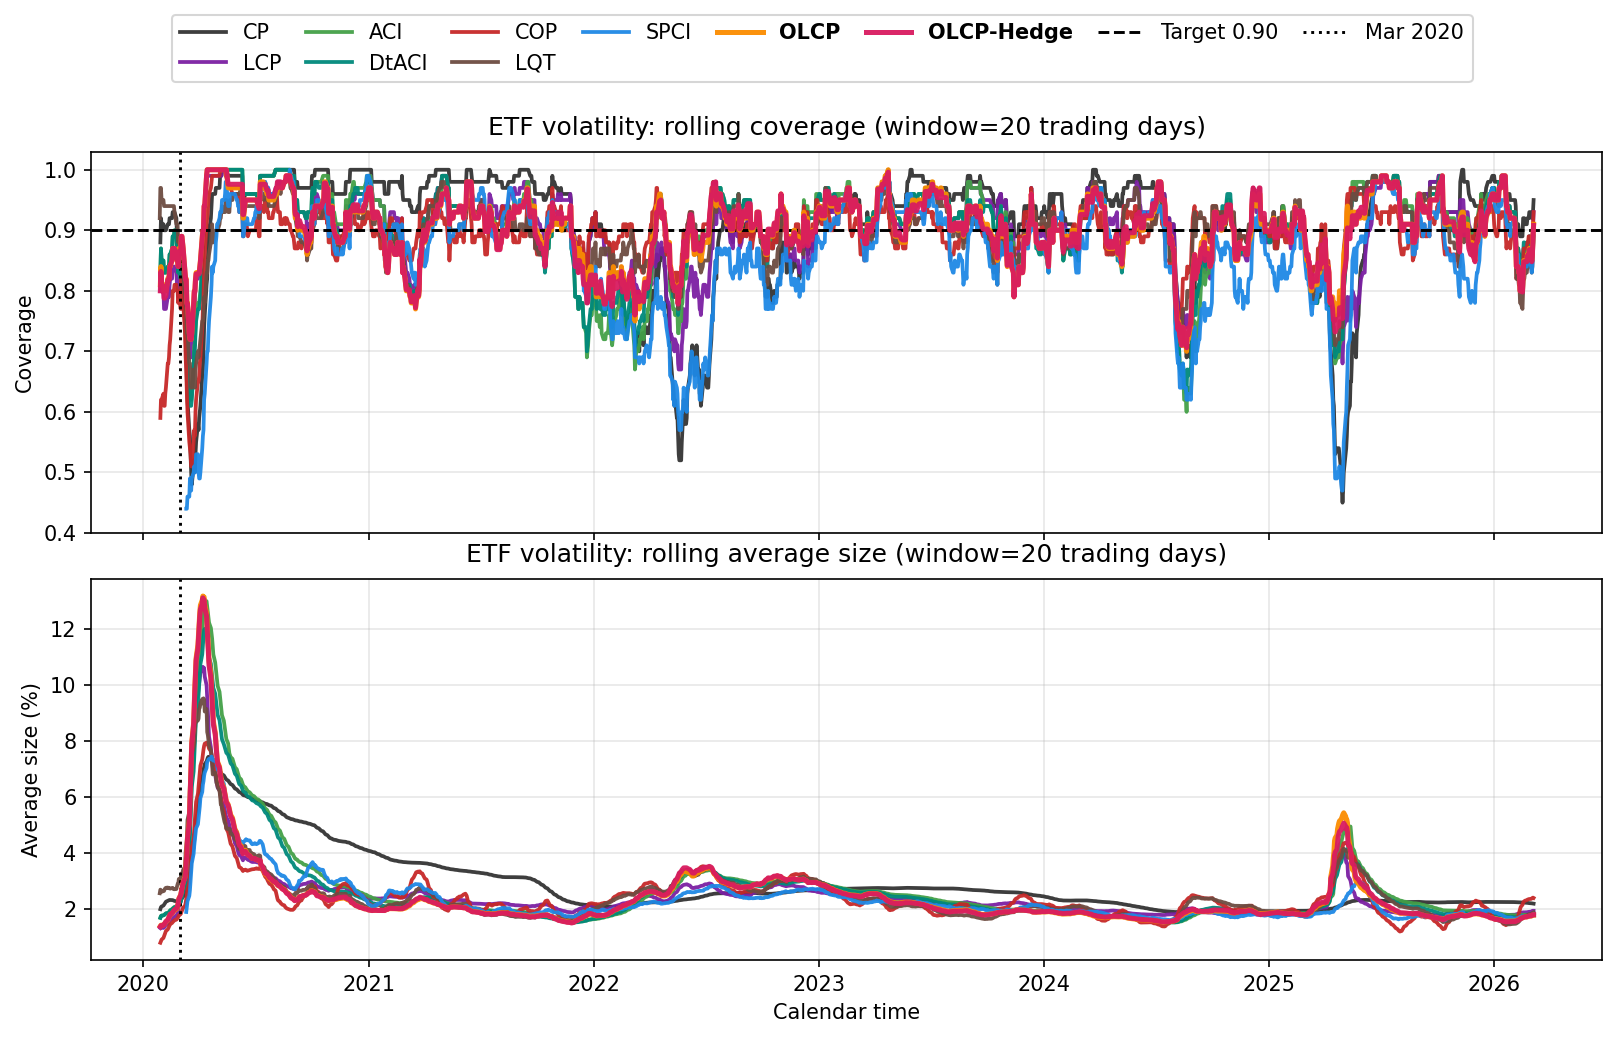

In [6]:
COLORS = dict(zip(METHOD_ORDER, [
    "#333333", "#7B1FA2", "#43A047", "#00897B", "#C62828",
    "#6D4C41", "#1E88E5", "#FB8C00", "#D81B60",
]))
LINESTYLES = {"cop": "--", "lqt": "-.", "spci": ":"}


def display_figure(fig):
    """Render and embed the figure in this notebook."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"hspace": 0.12})
for name in METHOD_ORDER:
    traces = pd.concat([results_by_seed[seed][name] for seed in SEEDS], ignore_index=True)
    traces["finite_size_pp"] = traces["size_pp"].replace([np.inf, -np.inf], np.nan)
    daily = traces.groupby("date")[["covered", "finite_size_pp"]].mean()
    rolling = daily.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
    for ax, metric in zip(axes, ("covered", "finite_size_pp")):
        ax.plot(rolling.index[ROLLING_WINDOW - 1:], rolling[metric].iloc[ROLLING_WINDOW - 1:],
                label=LABELS[name], color=COLORS[name], linestyle="-", alpha=0.95,
                linewidth=2.4 if name in ("olcp", "olcph") else 1.8,
                zorder=4 if name in ("olcp", "olcph") else 2)
axes[0].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1.4, label=f"Target {1 - ALPHA:.2f}")
axes[0].set_title(f"ETF volatility: rolling coverage (window={ROLLING_WINDOW} trading days)", pad=8)
axes[0].set_ylabel("Coverage")
axes[0].set_ylim(0.4, 1.03)
axes[1].set_title(f"ETF volatility: rolling average size (window={ROLLING_WINDOW} trading days)", pad=8)
axes[1].set_ylabel("Average size (%)")
axes[1].set_xlabel("Calendar time")
axes[0].axvline(pd.Timestamp("2020-03-01"), color="black", linestyle=":", linewidth=1.4, label="Mar 2020")
axes[1].axvline(pd.Timestamp("2020-03-01"), color="black", linestyle=":", linewidth=1.4)
locator = mdates.YearLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for ax in axes:
    ax.grid(True, alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
legend = fig.legend(
    handles, labels, loc="upper center", ncol=min(len(labels), 8),
    frameon=True, bbox_to_anchor=(0.5, 1.02), columnspacing=1.2,
    handlelength=2.2, fontsize=10,
)
for text in legend.get_texts():
    if text.get_text() in ("OLCP", "OLCP-Hedge"):
        text.set_fontweight("bold")
# Fixed subplot geometry.
fig.subplots_adjust(left=0.125, right=0.9, bottom=0.11, top=0.88, hspace=0.12)
display_figure(fig)


## VIX-regime analysis

Coverage and interval width for the bottom and top quartiles of lagged VIX.


Low VIX: lagged VIX <= 15.860; high VIX: lagged VIX >= 23.855


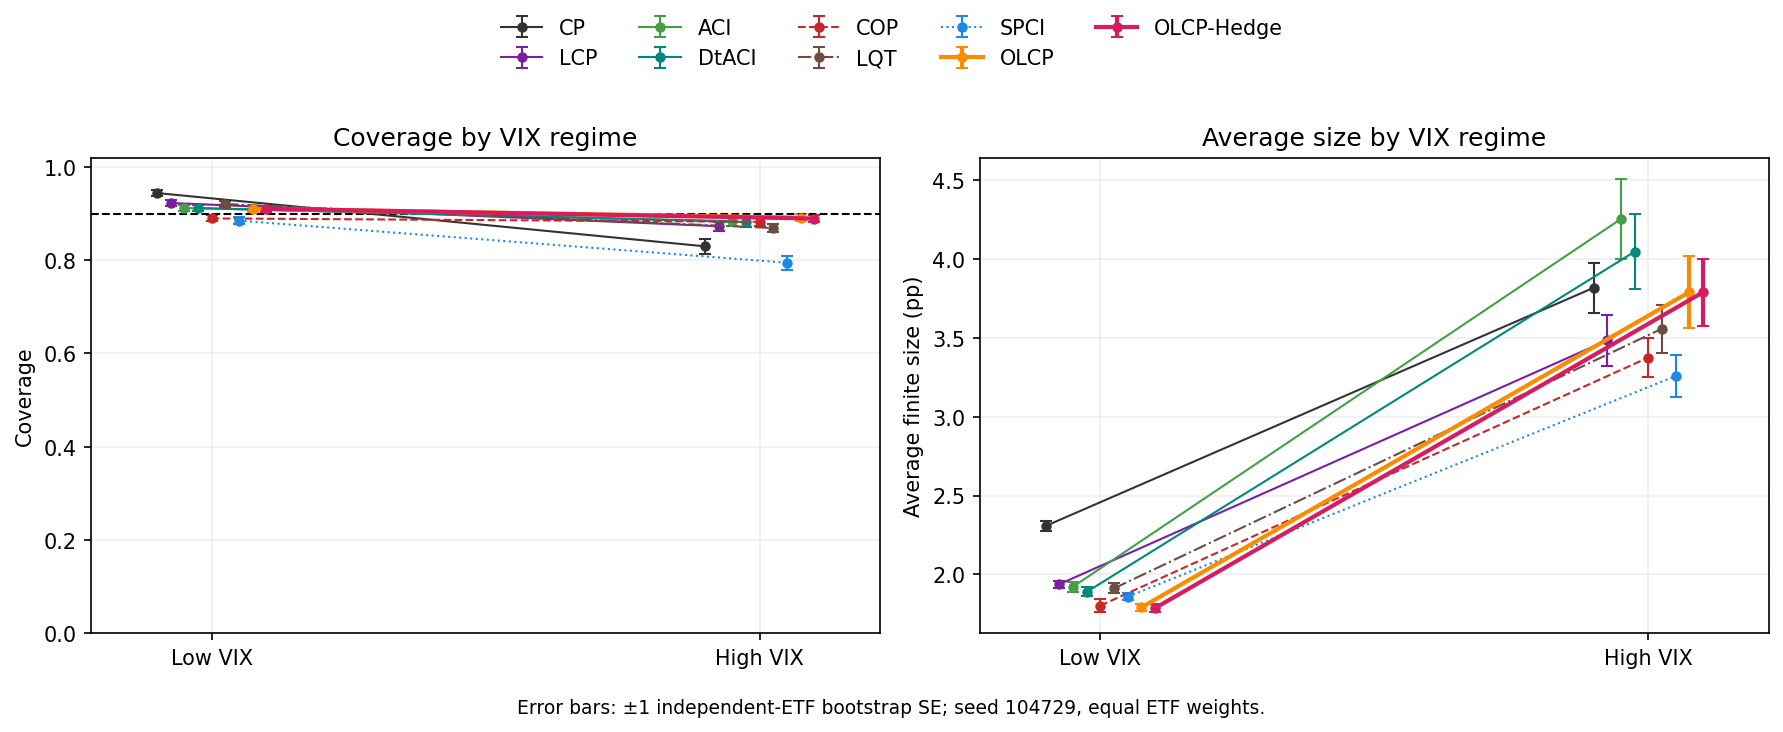

In [7]:
print(f"Low VIX: lagged VIX <= {low_threshold:.3f}; high VIX: lagged VIX >= {high_threshold:.3f}")
regime_rows = []
for regime in ("Low VIX", "High VIX"):
    for name in METHOD_ORDER:
        values = method_stats[name][regime]
        regime_rows.append({
            "Regime": regime, "Method": LABELS[name],
            "Coverage": values["coverage"], "Coverage SE": values["coverage_se"],
            "Average finite size (pp)": values["size"], "Size SE (pp)": values["size_se"],
            "Nonfinite intervals (%)": values["nonfinite_pct"],
            "ETF-date observations": values["observations"],
        })
regime_summary = pd.DataFrame(regime_rows).set_index(["Regime", "Method"])
display(regime_summary.style.format({k: v for k, v in FORMATS.items() if k in regime_summary.columns}, na_rep="undefined"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for j, name in enumerate(METHOD_ORDER):
    x = np.array([0, 1]) + (j - (len(METHOD_ORDER) - 1) / 2) * 0.025
    for ax, metric, se_key in zip(axes, ("coverage", "size"), ("coverage_se", "size_se")):
        ax.errorbar(x, [method_stats[name][key][metric] for key in ("Low VIX", "High VIX")],
                    yerr=[method_stats[name][key][se_key] for key in ("Low VIX", "High VIX")],
                    color=COLORS[name], label=LABELS[name], marker="o", markersize=4,
                    linewidth=2 if name in ("olcp", "olcph") else 1,
                    linestyle=LINESTYLES.get(name, "-"), capsize=3)
axes[0].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1)
axes[0].set_ylabel("Coverage")
axes[0].set_ylim(0, 1.02)
axes[1].set_ylabel("Average finite size (pp)")
for ax, title in zip(axes, ("Coverage by VIX regime", "Average size by VIX regime")):
    ax.set_title(title)
    ax.set_xticks([0, 1], ["Low VIX", "High VIX"])
    ax.set_xlim(-0.22, 1.22)
    ax.grid(alpha=0.2)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=5, frameon=False)
fig.text(0.5, 0.015, "Error bars: ±1 independent-ETF bootstrap SE; seed 104729, equal ETF weights.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.045, 1, 0.86))
display_figure(fig)
